# Real pairs: do rules and frozen scores pick better seeds than random sets?

`first_look.py` ran six real pairs over the weekend (7–8 Nov). This notebook only reads the results; nothing is run.

**Pairs.** All unweighted and undirected; A is the graph seeds are chosen from.
- **Worm (hermaphrodite):** C. elegans chemical (A) vs gap-junction (B) synapses, all 279 neurons, and the 247 neurons in the largest component of both graphs.
- **Worm (male):** the same for the male connectome, 167 neurons.
- **Enron:** e-mail in week 130 (A) vs week 131 or 132 (B), the largest component of both weeks.
- **Wikipedia:** English (A) vs French (B) articles, 1,382.

**Design.** 20% of each pair's vertices are test vertices, never seeds, and B's labels are shuffled once. At each budget:
- 30 random sets (15 for Wikipedia) from a pool of 1,000;
- round 1's six rules;
- the best set of the pool by each graph model's frozen score (ER, Chung–Lu, PAPER weights) and by degree.

**Variants.** Percolation, FAQ (3 runs per set; 1 for Wikipedia), and GOAT with regulariser 100 (ER's value) and 300 (Chung–Lu's and PAPER's).

**Caveat.** Test sets are small (28–56 vertices except Wikipedia's 276) and each rule is a single set per budget, so differences of a few points are within noise. Look for gains that hold across budgets and pairs.

In [1]:
import os
import sys
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import importlib

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == 'real_data_experiments':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from real_data_experiments import first_look as F
F = importlib.reload(F)   # picks up edits to first_look.py without restarting the kernel

pd.set_option('display.max_rows', 300)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 250)

## 1. The pairs

How much the two graphs of a pair overlap limits every method: the worm's chemical and gap-junction graphs share only about 10% of the chemical edges (edge correlation 0.17), the Enron weeks and Wikipedia far more. **Degree CV** is the spread of A's degrees (ER at mean degree 8 is about 0.35; Chung–Lu and PAPER are heavier-tailed).

In [2]:
per = F.per_set()
display(F.pair_table())

,vertices,test vertices,edges in A,edges in B,mean degree A,mean degree B,degree CV of A,isolated in B,edge correlation,share of A's edges in B,budgets
pair,,,,,,,,,,,
"Worm (hermaphrodite), all 279",279,56,1961,514,14.1,3.7,0.80,26,0.167,0.096,"25, 50, 100, 150, 200"
"Worm, common largest component (247)",247,49,1617,508,13.1,4.1,0.84,0,0.182,0.115,"25, 50, 100, 150"
"Worm (male), 167",167,33,1690,913,20.2,10.9,0.62,2,0.365,0.309,"10, 20, 40, 60, 80"
"Enron, weeks 130 vs 131 (145)",145,29,377,363,5.2,5.0,1.38,0,0.891,0.878,"5, 10, 20, 40, 60"
"Enron, weeks 130 vs 132 (141)",141,28,372,360,5.3,5.1,1.37,0,0.765,0.761,"5, 10, 20, 40, 60"
"Wikipedia, English vs French (1,382)",1382,276,18857,14973,27.3,21.7,1.30,59,0.464,0.422,"10, 20, 30, 50, 75"


## 2. Accuracy against seeds

One panel per pair: random sets' mean (grey line) and 10th–90th percentile (grey band), and four choices of seeds: the distinguishing and hub-free distinguishing rules, top degree, and the best of 1,000 random sets by the ER score. Change `methods=` to show others (names in `F.METHODS`).

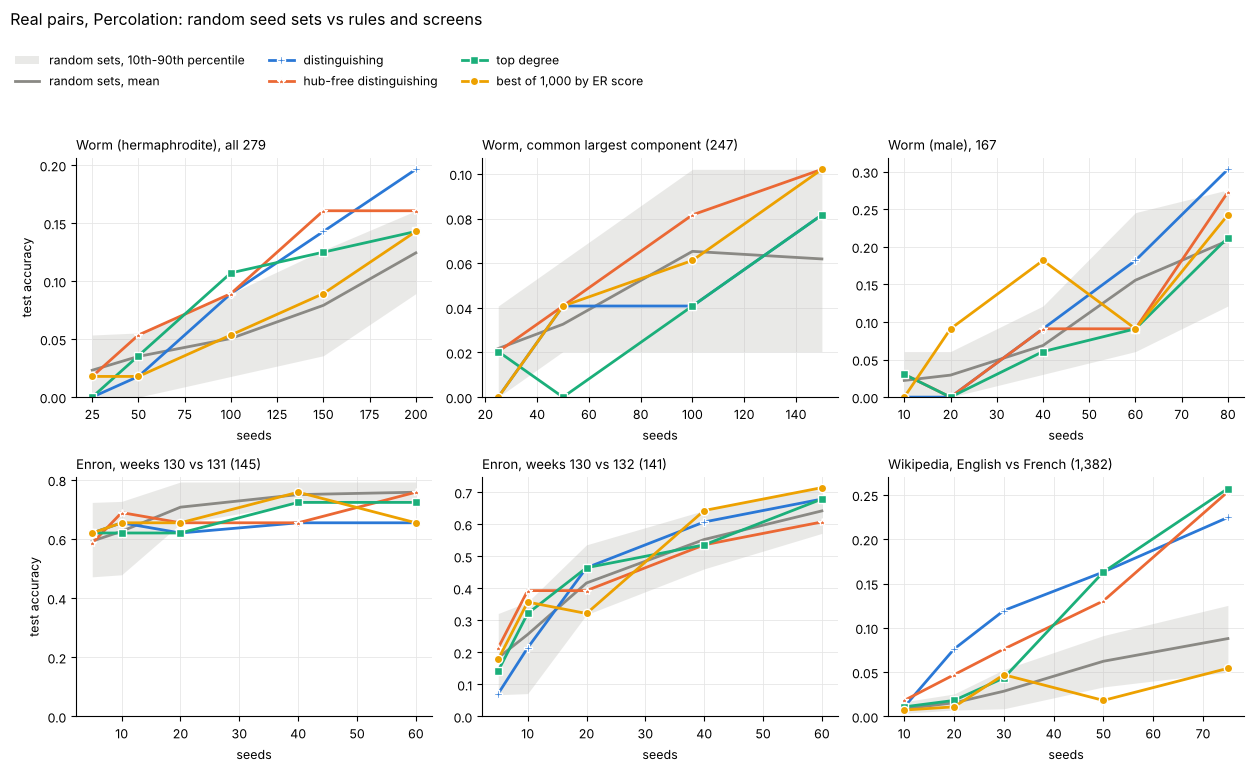

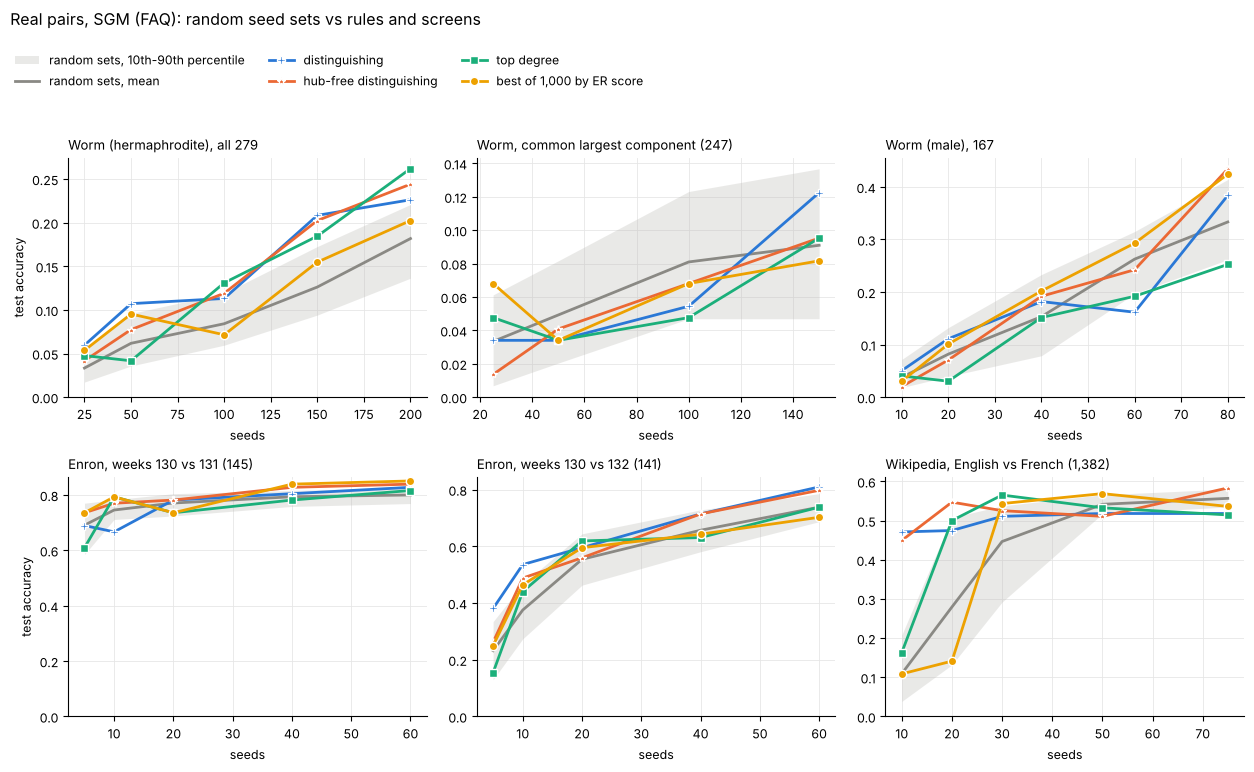

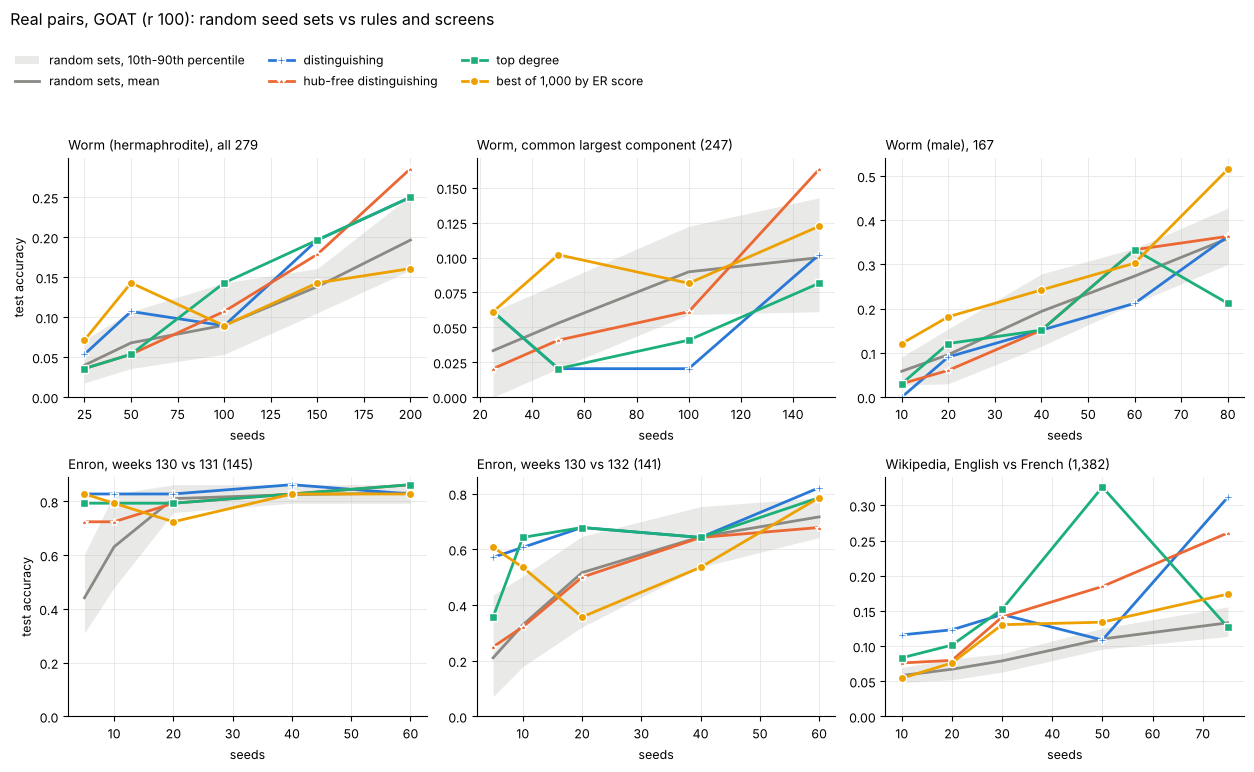

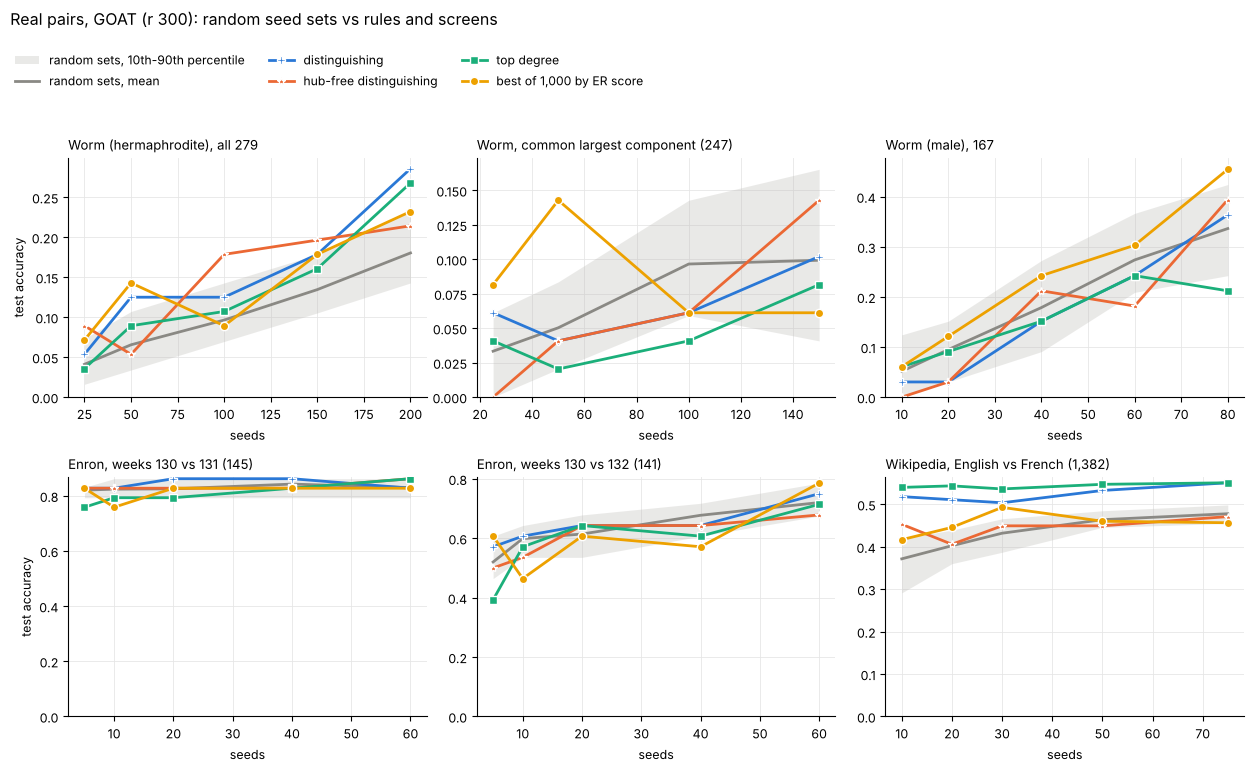

In [3]:
for variant in F.VARIANTS:
    F.plot_budgets(per, variant)
    plt.show()

### The numbers (FAQ)

Random sets' mean, SD, 10th and 90th percentiles and best set (of 30), then every rule and screen. Set `variant` to `'goat_r100'`, `'goat_r300'` or `'percolation'` for the others.

In [4]:
variant = 'faq'
display(F.budget_table(per, variant))

random mean  random SD  random 10th pct  random 90th pct  best random set  random sets  top degree  top harmonic  clustered (pair mass)  spread (coverage)  distinguishing  hub-free distinguishing  \
pair                                 budget                                                                                                                                                                                                        
Worm (hermaphrodite), all 279        25            0.033      0.016            0.017            0.054            0.065           30       0.048         0.054                  0.048              0.042           0.060                    0.042   
                                     50            0.062      0.023            0.036            0.096            0.119           30       0.042         0.065                  0.095              0.048           0.107                    0.077   
                                     100           0.084      0.024            0.060            0.119            0.131           30       0.131         0.137                  0.060              0.101           0.113                    0.119   
                                     150           0.126      0.032            0.094            0.173            0.202           30       0.185         0.143                  0.137              0.143           0.208                    0.202   
                                     200           0.182      0.038            0.136            0.221            0.262           30       0.262         0.190                  0.161              0.238           0.226                    0.244   
Worm, common largest component (247) 25            0.033      0.020            0.007            0.061            0.068           30       0.048         0.020                  0.041              0.020           0.034                    0.014   
                                     50            0.049      0.022            0.020            0.082            0.095           30       0.034         0.061                  0.061              0.027           0.034                    0.041   
                                     100           0.081      0.030            0.047            0.123            0.150           30       0.048         0.095                  0.136              0.054           0.054                    0.068   
                                     150           0.091      0.032            0.047            0.137            0.156           30       0.095         0.095                  0.122              0.122           0.122                    0.095   
Worm (male), 167                     10            0.038      0.025            0.018            0.072            0.091           30       0.040         0.040                  0.010              0.010           0.051                    0.020   
                                     20            0.082      0.040            0.039            0.132            0.172           30       0.030         0.010                  0.101              0.101           0.111                    0.071   
                                     40            0.153      0.058            0.079            0.233            0.273           30       0.152         0.152                  0.152              0.182           0.182                    0.192   
                                     60            0.263      0.057            0.197            0.315            0.364           30       0.192         0.323                  0.323              0.414           0.162                    0.242   
                                     80            0.333      0.063            0.262            0.414            0.444           30       0.253         0.374                  0.333              0.222           0.384                    0.434   
Enron, weeks 130 vs 131 (145)        5             0.691      0.067            0.585            0.770            0.816           30       0.6

## 3. Gains over random sets

Each rule's and screen's test accuracy minus the random sets' mean at the same pair, variant and budget, averaged over budgets. **Share above random** counts the (pair, budget) cases where the method beat the random mean.

In [5]:
display(F.gain_table(per))

pair                                          Worm (hermaphrodite), all 279  Worm, common largest component (247)  Worm (male), 167  Enron, weeks 130 vs 131 (145)  Enron, weeks 130 vs 132 (141)  Wikipedia, English vs French (1,382)  all pairs  \
variant      method                                                                                                                                                                                                                                  
Percolation  top degree                                               0.020                                -0.010            -0.018                         -0.025                          0.019                                 0.058      0.008   
             top harmonic                                            -0.002                                 0.006            -0.012                         -0.032                         -0.046                                 0.071     -0.003   
             clustered (pair mass)                                    0.030                                 0.011             0.024                         -0.011                          0.047                                 0.033      0.023   
             spread (coverage)                                        0.020                                -0.010            -0.018                         -0.039                          0.076                                 0.073      0.018   
             distinguishing                                           0.027                                -0.005             0.018                         -0.046                         -0.003                                 0.078      0.012   
             hub-free distinguishing                                  0.034                                 0.016             0.000                         -0.018                          0.019                                 0.064      0.019   
             best of 1,000 by ER score                                0.002                                 0.006             0.024                         -0.018                          0.033                                -0.013      0.006   
             best of 1,000 by Chung-Lu score                         -0.016                                -0.005             0.012                         -0.094                         -0.003                                -0.001     -0.018   
             best of 1,000 by PAPER score                            -0.016                                -0.005             0.024                         -0.094                          0.004                                -0.001     -0.015   
             best of 1,000 by degree                                 -0.009                                -0.015             0.006                          0.023                          0.040                                -0.001      0.008   
SGM (FAQ)    top degree                                               0.036                                -0.007            -0.040                         -0.013                          0.005                                 0.068      0.009   
             top harmonic                                             0.020                                 0.004             0.006                         -0.020                         -0.009                                 0.066      0.012   
             clustered (pair mass)                                    0.003                                 0.027             0.010                          0.017                         -0.004                                 0.080      0.022   
             spread (coverage)                                        0.017                                -0.007             0.012                          0.015                          0.024                                 0.104      0.029   
             distinguishing                                     

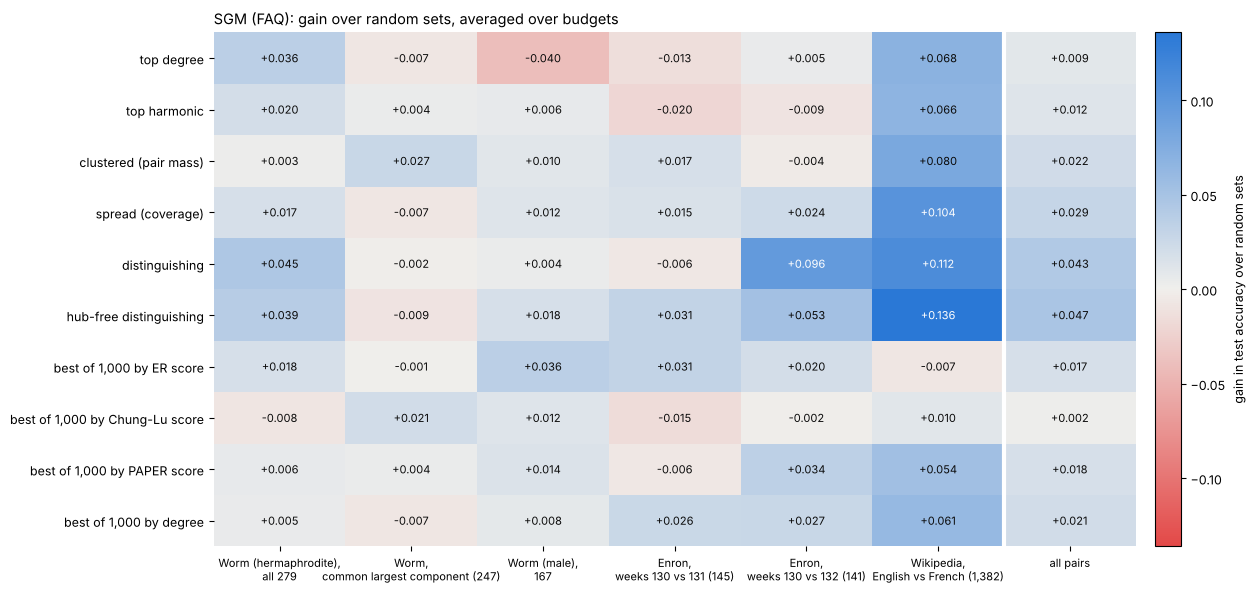

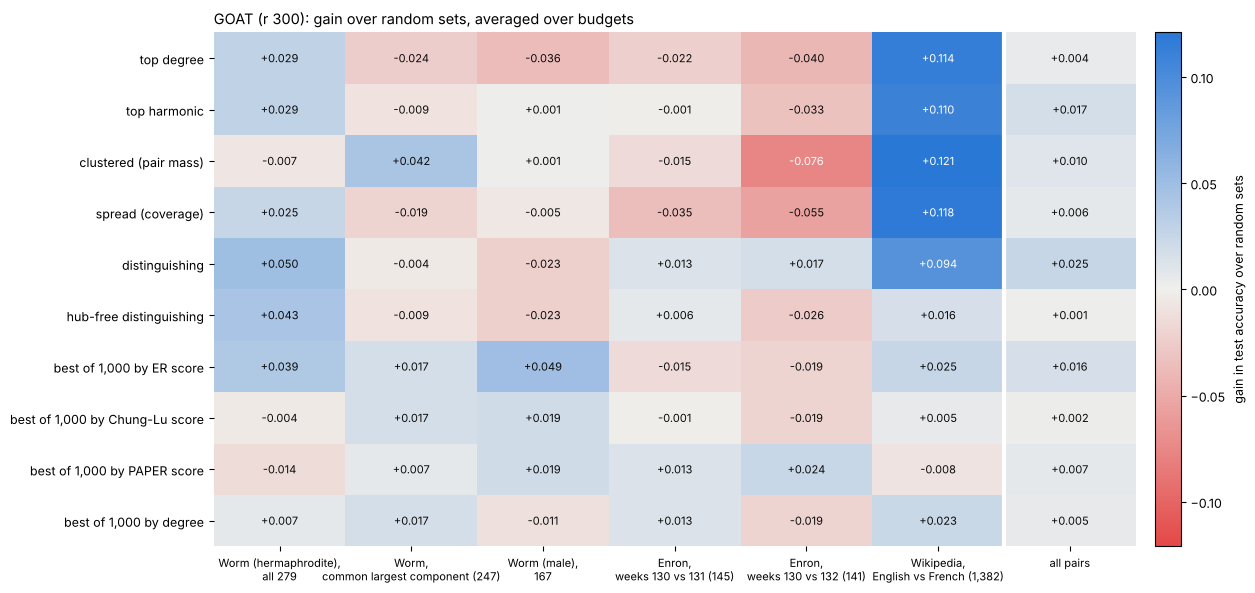

In [6]:
for variant in ('faq', 'goat_r300'):
    F.plot_gain_heatmap(per, variant)
    plt.show()

## 4. Weighted score vs performance on real pairs

Rows are pairs and columns budgets. Grey: the random sets; orange and dark shapes: round 1's rules; blues and aqua: the screens. The title gives the Spearman correlation between the score and accuracy over the random sets. Change `score` to `'score_cl'`, `'score_paper'` or `'z_degree'`.

With 30 random sets and small test sets, a single panel's correlation is noisy; the table after the figures averages it over budgets.

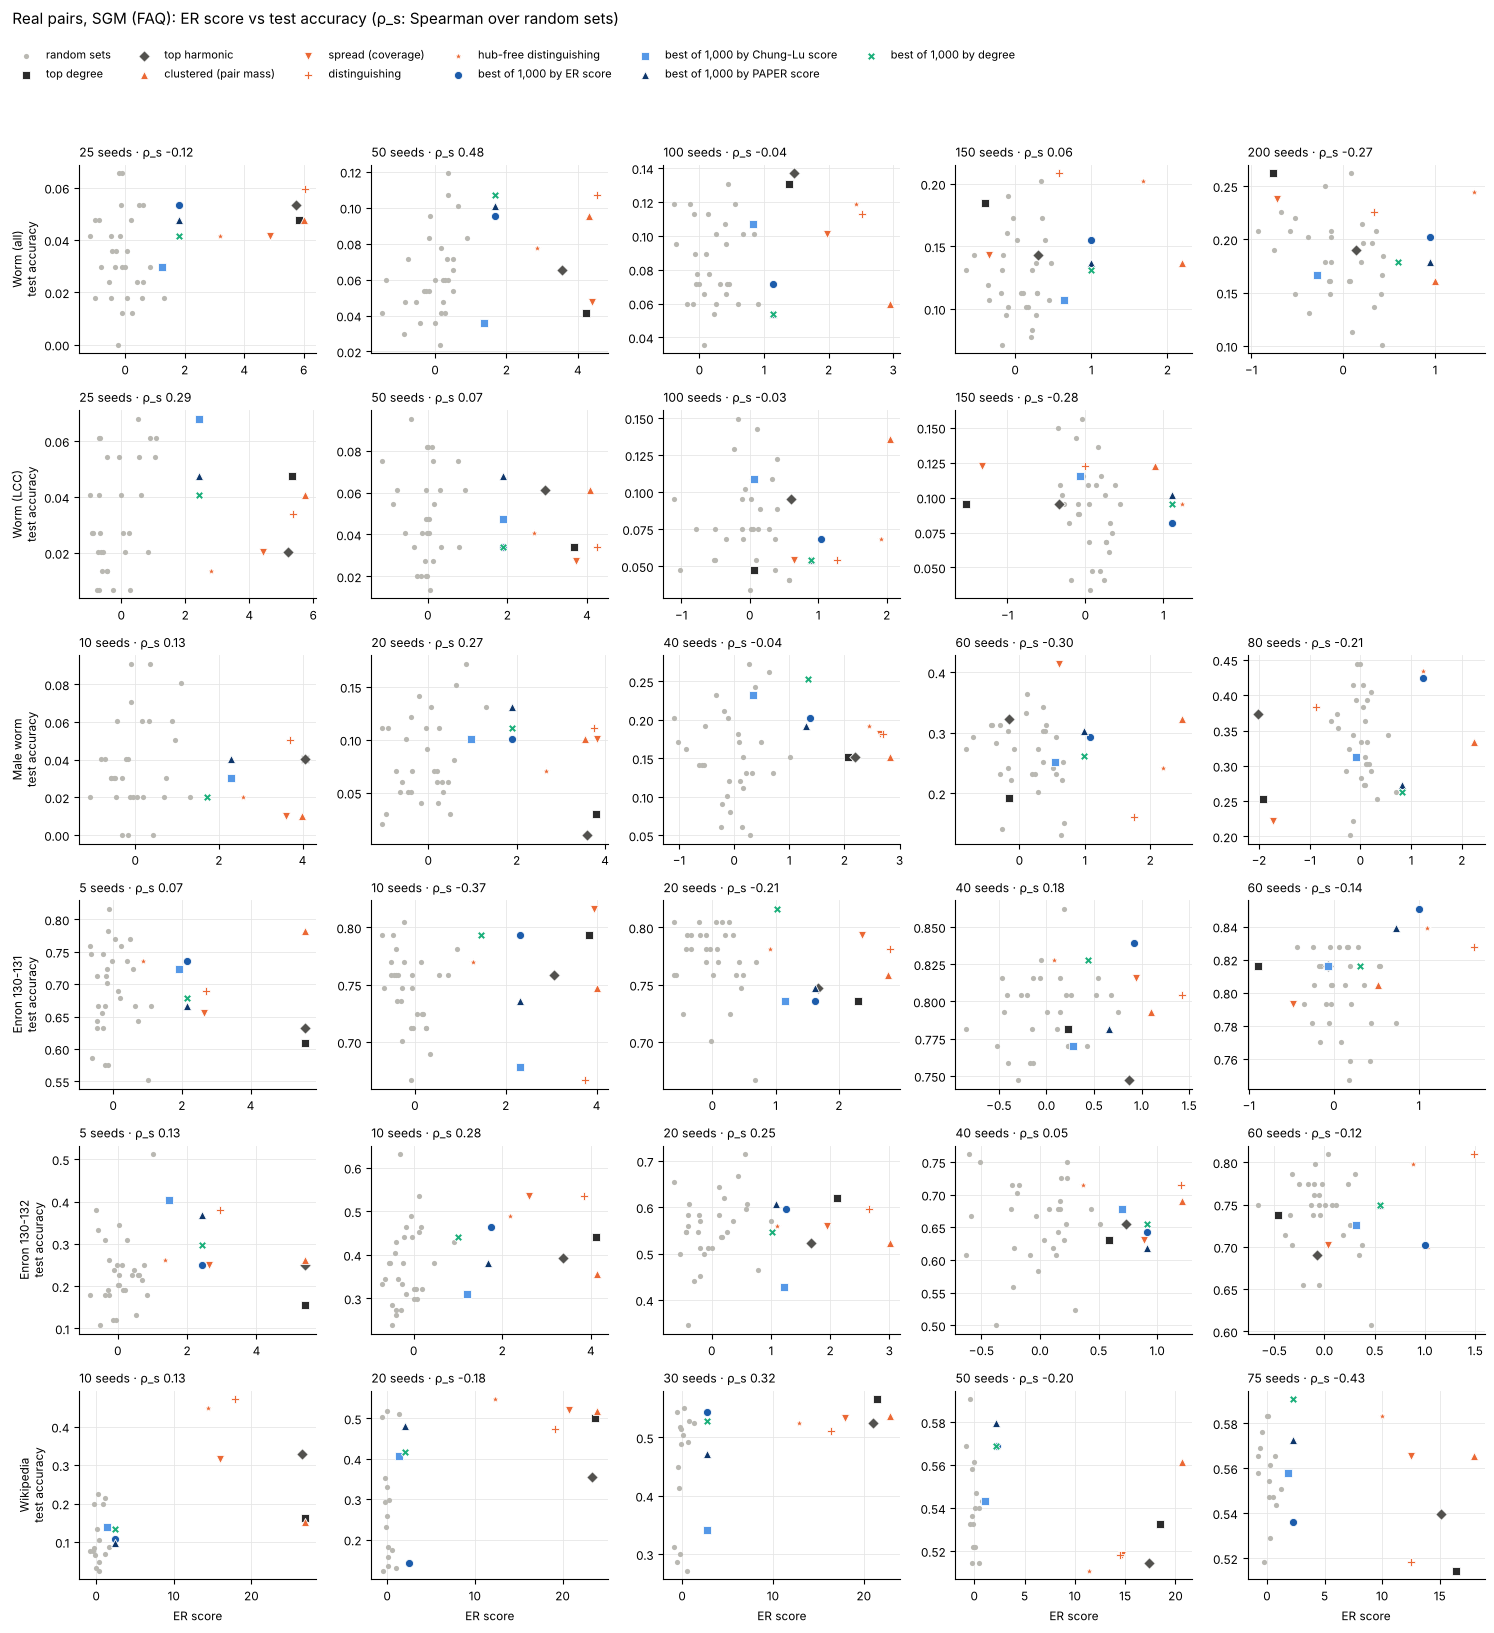

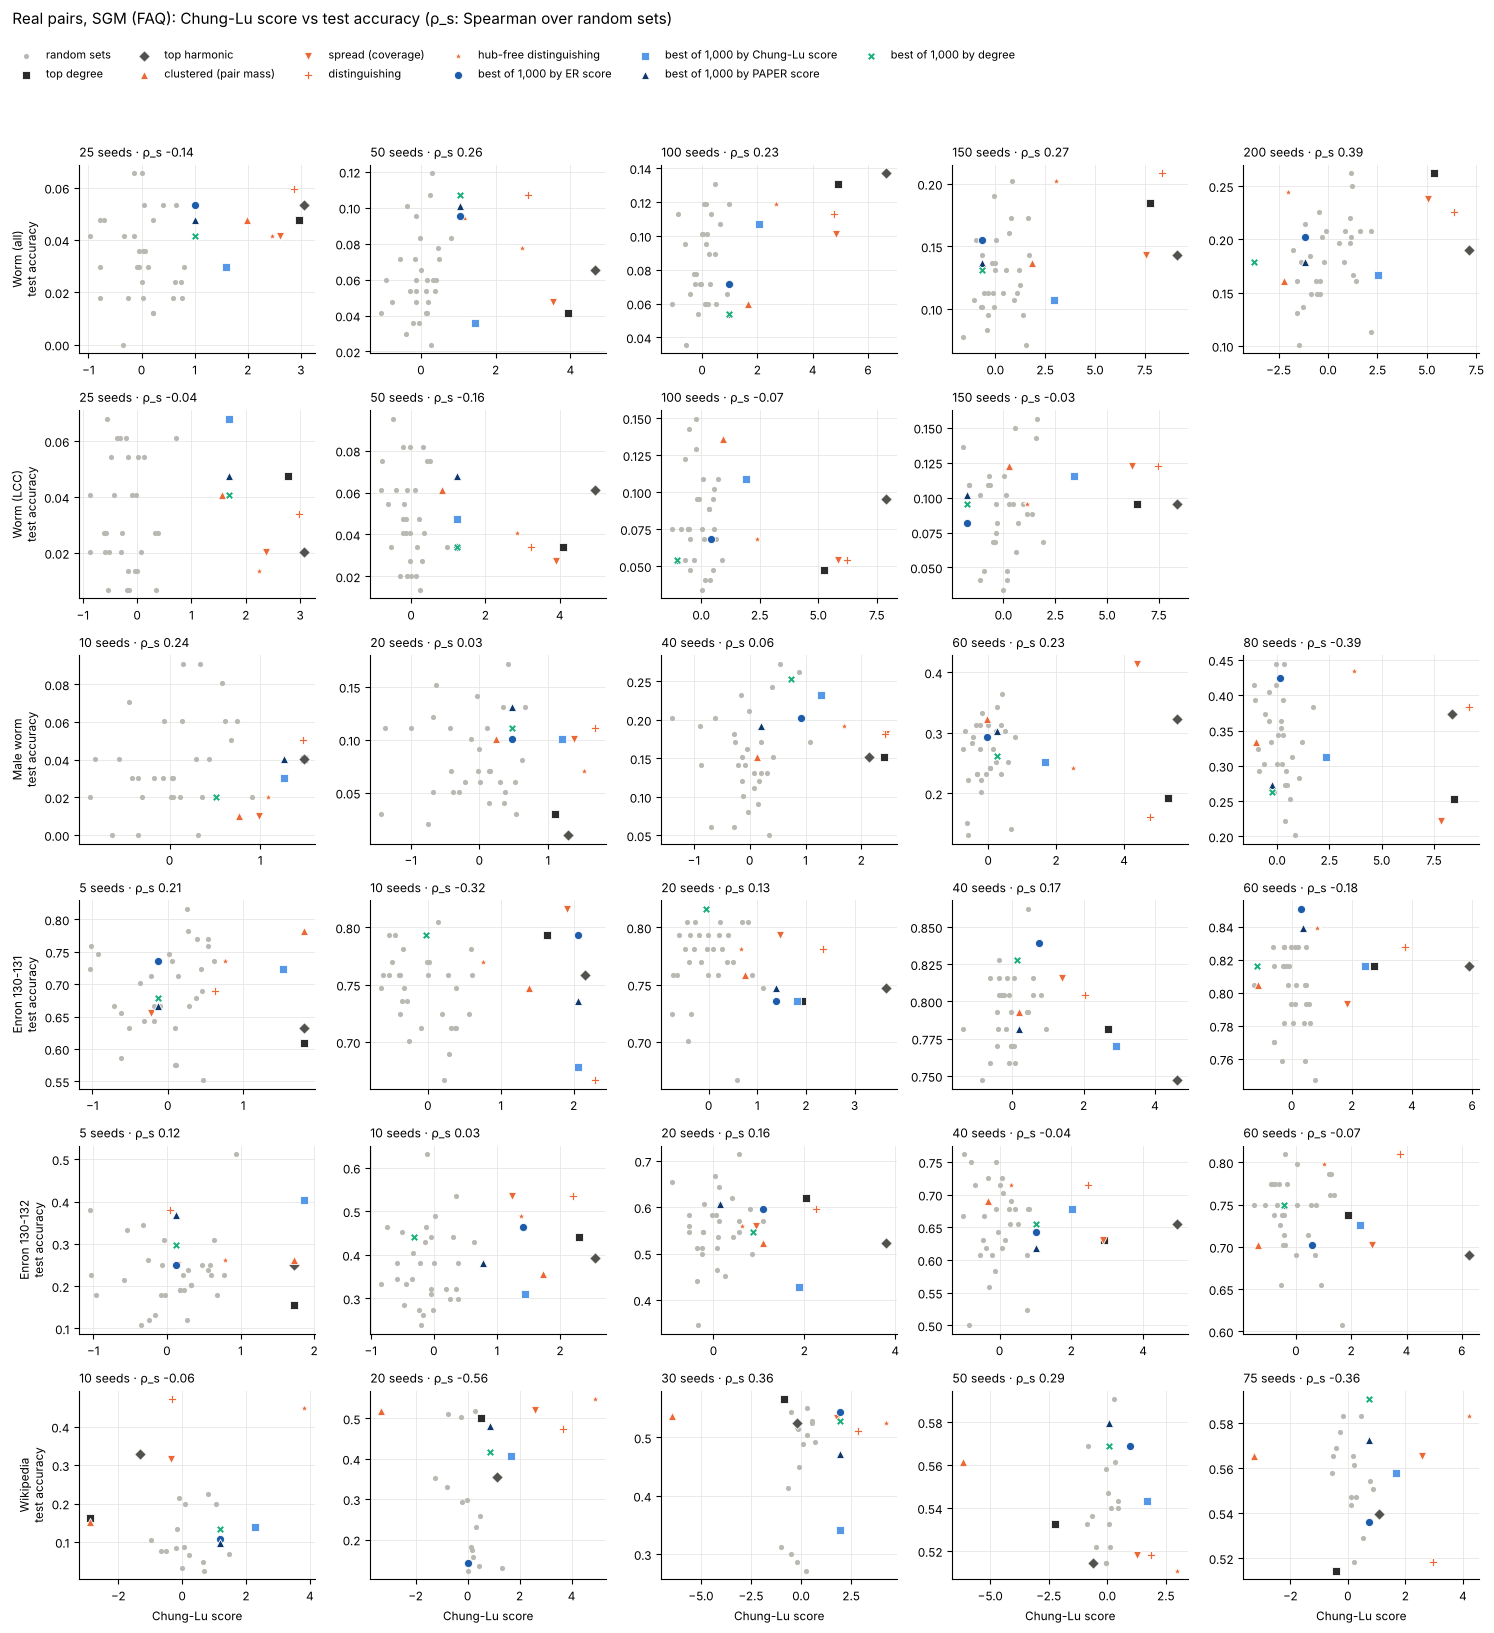

In [7]:
for score in ('score_er', 'score_cl'):
    F.plot_scores(per, 'faq', score)
    plt.show()

In [8]:
display(F.score_table(per))

ER score  Chung-Lu score  PAPER score  degree (z)
pair                                 variant                                                        
Worm (hermaphrodite), all 279        Percolation      -0.04            0.03         0.04       -0.02
                                     SGM (FAQ)         0.02            0.20        -0.10       -0.11
                                     GOAT (r 100)      0.13            0.10         0.11        0.00
                                     GOAT (r 300)      0.10            0.16         0.12       -0.16
Worm, common largest component (247) Percolation      -0.12            0.02        -0.02       -0.19
                                     SGM (FAQ)         0.01           -0.08         0.03        0.05
                                     GOAT (r 100)     -0.10           -0.10        -0.07        0.01
                                     GOAT (r 300)     -0.09            0.01         0.05       -0.11
Worm (male), 167                     Percolation      -0.05            0.01         0.01       -0.05
                                     SGM (FAQ)        -0.03            0.03         0.01       -0.02
                                     GOAT (r 100)     -0.10            0.01         0.00       -0.03
                                     GOAT (r 300)     -0.14           -0.05        -0.04       -0.04
Enron, weeks 130 vs 131 (145)        Percolation      -0.01           -0.02        -0.03       -0.01
                                     SGM (FAQ)        -0.09            0.00        -0.04       -0.02
                                     GOAT (r 100)      0.08           -0.10        -0.03        0.21
                                     GOAT (r 300)     -0.02           -0.08        -0.04        0.08
Enron, weeks 130 vs 132 (141)        Percolation      -0.07           -0.09        -0.10        0.07
                                     SGM (FAQ)         0.12            0.04         0.20        0.21
                                     GOAT (r 100)      0.03           -0.33        -0.15        0.33
                                     GOAT (r 300)     -0.17           -0.19        -0.09        0.05
Wikipedia, English vs French (1,382) Percolation       0.02            0.10         0.06       -0.02
                                     SGM (FAQ)        -0.07           -0.07         0.01       -0.00
                                     GOAT (r 100)     -0.12            0.03         0.08       -0.15
                                     GOAT (r 300)      0.09           -0.09        -0.04        0.04

## 5. The four solver variants

Random sets' mean test accuracy for each variant. GOAT's regulariser matters a lot on some pairs (Wikipedia, Enron), so a fixed value is not safe on real graphs.

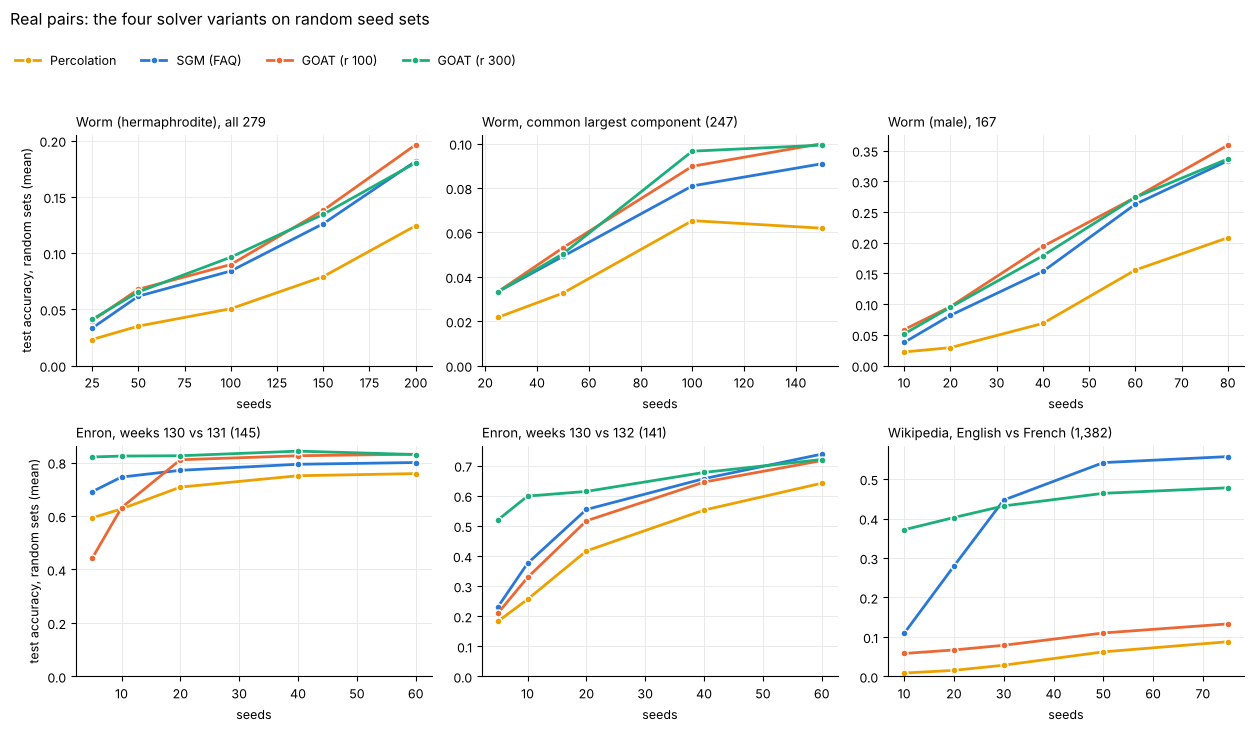

variant                                      Percolation  SGM (FAQ)  GOAT (r 100)  GOAT (r 300)
pair                                 budget                                                    
Worm (hermaphrodite), all 279        25            0.023      0.033         0.040         0.041
                                     50            0.035      0.062         0.068         0.065
                                     100           0.051      0.084         0.090         0.096
                                     150           0.079      0.126         0.138         0.135
                                     200           0.124      0.182         0.196         0.180
Worm, common largest component (247) 25            0.022      0.033         0.033         0.033
                                     50            0.033      0.049         0.053         0.050
                                     100           0.065      0.081         0.090         0.097
                                     150           0.062      0.091         0.100         0.099
Worm (male), 167                     10            0.022      0.038         0.059         0.052
                                     20            0.029      0.082         0.096         0.095
                                     40            0.069      0.153         0.194         0.179
                                     60            0.156      0.263         0.274         0.274
                                     80            0.208      0.333         0.359         0.336
Enron, weeks 130 vs 131 (145)        5             0.593      0.691         0.441         0.821
                                     10            0.626      0.746         0.631         0.824
                                     20            0.708      0.771         0.810         0.825
                                     40            0.751      0.793         0.825         0.843
                                     60            0.759      0.800         0.831         0.830
Enron, weeks 130 vs 132 (141)        5             0.183      0.232         0.211         0.520
                                     10            0.256      0.375         0.329         0.599
                                     20            0.417      0.554         0.517         0.614
                                     40            0.552      0.657         0.645         0.677
                                     60            0.642      0.738         0.717         0.720
Wikipedia, English vs French (1,382) 10            0.009      0.109         0.058         0.371
                                     20            0.015      0.279         0.067         0.402
                                     30            0.029      0.447         0.079         0.432
                                     50            0.062      0.542         0.110         0.464
                                     75            0.088      0.557         0.133         0.478

In [9]:
F.plot_variants(per)
plt.show()
display(F.variant_table(per))

## 6. The worm by neuron class (FAQ)

**Same class:** the share of test neurons matched to a neuron of the same class (motor, interneuron, sensory). A random matching would get `same_class_chance()`, about 0.36. Even where exact accuracy is low (3–26%), about half the test neurons land on a neuron of the right class.

In [10]:
print(f"Same class by chance: {F.same_class_chance('worm'):.3f}")
display(F.class_table(per, 'worm', 'faq'))
display(F.class_breakdown(per, 'worm', 'faq'))

Same class by chance: 0.359


test accuracy                             same class                            
budget                                    25     50     100    150    200        25     50     100    150    200
random sets (mean)                      0.033  0.062  0.084  0.126  0.182      0.461  0.503  0.505  0.513  0.526
top degree                              0.048  0.042  0.131  0.185  0.262      0.435  0.440  0.571  0.542  0.607
top harmonic                            0.054  0.065  0.137  0.143  0.190      0.446  0.530  0.512  0.536  0.577
clustered (pair mass)                   0.048  0.095  0.060  0.137  0.161      0.476  0.446  0.452  0.542  0.577
spread (coverage)                       0.042  0.048  0.101  0.143  0.238      0.429  0.470  0.530  0.560  0.565
distinguishing                          0.060  0.107  0.113  0.208  0.226      0.518  0.446  0.577  0.595  0.565
hub-free distinguishing                 0.042  0.077  0.119  0.202  0.244      0.476  0.476  0.482  0.571  0.542
best of 1,000 by ER score               0.054  0.095  0.071  0.155  0.202      0.452  0.464  0.506  0.494  0.506
best of 1,000 by Chung-Lu score         0.030  0.036  0.107  0.107  0.167      0.369  0.494  0.548  0.560  0.560
best of 1,000 by PAPER score            0.048  0.101  0.054  0.137  0.179      0.476  0.512  0.536  0.518  0.524
best of 1,000 by degree                 0.042  0.107  0.054  0.131  0.179      0.440  0.476  0.560  0.506  0.470

,motor,interneuron,sensory,all test neurons
random sets (mean),0.096,0.102,0.095,0.097
top degree,0.105,0.204,0.111,0.133
top harmonic,0.095,0.160,0.116,0.118
clustered (pair mass),0.097,0.133,0.071,0.100
spread (coverage),0.077,0.191,0.102,0.114
distinguishing,0.126,0.196,0.120,0.143
hub-free distinguishing,0.162,0.084,0.147,0.137
"best of 1,000 by ER score",0.115,0.142,0.089,0.115
"best of 1,000 by Chung-Lu score",0.087,0.107,0.076,0.089
"best of 1,000 by PAPER score",0.097,0.142,0.076,0.104


## Reading the results

- **The overlap of the two graphs sets the ceiling.** The worm (edge correlation 0.17) stays below about 26% at 200 seeds whatever the seeds; random sets get 18%, in line with the published ~16%.
- **Rules help, most at small budgets and on the larger, better-matched pairs.** On Wikipedia the distinguishing rules reach 47% at 10 seeds against 11% for random sets; on Enron 130–132 they help at 5–10 seeds. On the worm, top degree and the distinguishing rules gain a few points at 150–200 seeds.
- **The frozen scores do not carry over yet.** Their correlation with accuracy among random sets is inconsistent in sign, and picking the best of 1,000 random sets by score is about as good as random. As in the simulations, screening random sets cannot reach the sets the rules build.
- **GOAT's regulariser matters on real graphs**, sometimes more than the seeds.